In [74]:
import torch
import torchvision
from torchvision import datasets

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128


In [75]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 50000
Test samples: 10000


In [76]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Label:", label)
print("Image size:", image.size)

Image type: <class 'PIL.Image.Image'>
Label: 6
Image size: (32, 32)


In [77]:
classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Class:", classes[label])

Class: frog


In [78]:
from torchvision import transforms

to_tensor = transforms.ToTensor()

image_tensor = to_tensor(image)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

Tensor shape: torch.Size([3, 32, 32])
Tensor dtype: torch.float32
Minimum value: 0.0
Maximum value: 1.0


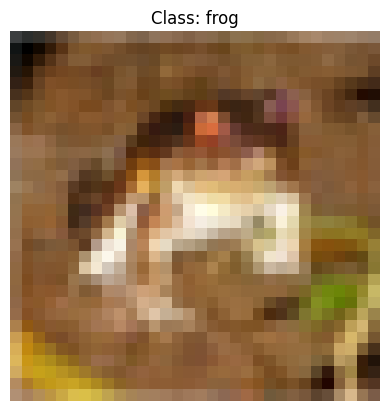

In [79]:
import matplotlib.pyplot as plt

plt.imshow(image)
plt.title(f"Class: {classes[label]}")
plt.axis("off");

In [80]:
print(image_tensor.shape)

print("\nRed channel:")
print(image_tensor[0])

print("\nGreen channel:")
print(image_tensor[1])

print("\nBlue channel:")
print(image_tensor[2])

torch.Size([3, 32, 32])

Red channel:
tensor([[0.2314, 0.1686, 0.1961,  ..., 0.6196, 0.5961, 0.5804],
        [0.0627, 0.0000, 0.0706,  ..., 0.4824, 0.4667, 0.4784],
        [0.0980, 0.0627, 0.1922,  ..., 0.4627, 0.4706, 0.4275],
        ...,
        [0.8157, 0.7882, 0.7765,  ..., 0.6275, 0.2196, 0.2078],
        [0.7059, 0.6784, 0.7294,  ..., 0.7216, 0.3804, 0.3255],
        [0.6941, 0.6588, 0.7020,  ..., 0.8471, 0.5922, 0.4824]])

Green channel:
tensor([[0.2431, 0.1804, 0.1882,  ..., 0.5176, 0.4902, 0.4863],
        [0.0784, 0.0000, 0.0314,  ..., 0.3451, 0.3255, 0.3412],
        [0.0941, 0.0275, 0.1059,  ..., 0.3294, 0.3294, 0.2863],
        ...,
        [0.6667, 0.6000, 0.6314,  ..., 0.5216, 0.1216, 0.1333],
        [0.5451, 0.4824, 0.5647,  ..., 0.5804, 0.2431, 0.2078],
        [0.5647, 0.5059, 0.5569,  ..., 0.7216, 0.4627, 0.3608]])

Blue channel:
tensor([[0.2471, 0.1765, 0.1686,  ..., 0.4235, 0.4000, 0.4039],
        [0.0784, 0.0000, 0.0000,  ..., 0.2157, 0.1961, 0.2235],
       

In [81]:
from torchvision import transforms, datasets

transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    transform=transform,
    download=True
)

In [82]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image shape:", image.shape)
print("Label:", label)
print("Class:", classes[label])

Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 32, 32])
Label: 6
Class: frog


In [83]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Training batches: 782
Test batches: 157


In [84]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)

Images shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])
Images dtype: torch.float32
Labels dtype: torch.int64


In [85]:
from collections import Counter

train_labels = [label for _, label in train_dataset]

counts = Counter(train_labels)

for class_id, count in sorted(counts.items()):
    print(f"{class_id}: {classes[class_id]:10s} → {count}")

0: airplane   → 5000
1: automobile → 5000
2: bird       → 5000
3: cat        → 5000
4: deer       → 5000
5: dog        → 5000
6: frog       → 5000
7: horse      → 5000
8: ship       → 5000
9: truck      → 5000


In [86]:
from torch.utils.data import random_split

train_size = 45_000
val_size = 5_000

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [87]:
train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 704
Validation batches: 79
Test batches: 157


In [88]:
train_images, train_labels = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))
test_images, test_labels = next(iter(test_loader))

print("Train:")
print("  Images:", train_images.shape)
print("  Labels:", train_labels.shape)

print("\nValidation:")
print("  Images:", val_images.shape)
print("  Labels:", val_labels.shape)

print("\nTest:")
print("  Images:", test_images.shape)
print("  Labels:", test_labels.shape)

Train:
  Images: torch.Size([64, 3, 32, 32])
  Labels: torch.Size([64])

Validation:
  Images: torch.Size([64, 3, 32, 32])
  Labels: torch.Size([64])

Test:
  Images: torch.Size([64, 3, 32, 32])
  Labels: torch.Size([64])


In [89]:
import torch.nn as nn

baseline_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
)

print(baseline_cnn)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=10, bias=True)
)


In [90]:
output = baseline_cnn(train_images)

print("Input shape:", train_images.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [91]:
total_params = sum(p.numel() for p in baseline_cnn.parameters())

print("Total parameters:", total_params)

Total parameters: 60362


In [92]:
for name, param in baseline_cnn.named_parameters():
    print(name, param.shape, param.numel())

0.weight torch.Size([32, 3, 3, 3]) 864
0.bias torch.Size([32]) 32
3.weight torch.Size([64, 32, 3, 3]) 18432
3.bias torch.Size([64]) 64
7.weight torch.Size([10, 4096]) 40960
7.bias torch.Size([10]) 10


In [93]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

baseline_cnn = baseline_cnn.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    baseline_cnn.parameters(),
    lr=0.01
)

print("Device:", device)
print("Model device:", next(baseline_cnn.parameters()).device)

Device: cuda
Model device: cuda:0


In [94]:
# Get one batch
images, labels = next(iter(train_loader))

# Move data to GPU
images = images.to(device)
labels = labels.to(device)

# 1. Clear old gradients
optimizer.zero_grad()

# 2. Forward pass
outputs = baseline_cnn(images)

# 3. Calculate loss
loss = criterion(outputs, labels)

# 4. Backpropagation
loss.backward()

# 5. Update weights
optimizer.step()

print("Images:", images.shape)
print("Outputs:", outputs.shape)
print("Loss:", loss.item())

Images: torch.Size([64, 3, 32, 32])
Outputs: torch.Size([64, 10])
Loss: 2.305609703063965


In [95]:
print("Conv1 weight gradient shape:",
      baseline_cnn[0].weight.grad.shape)

print("Conv1 weight gradient mean:",
      baseline_cnn[0].weight.grad.mean().item())

print("Conv1 weight gradient std:",
      baseline_cnn[0].weight.grad.std().item())

print("Linear weight gradient shape:",
      baseline_cnn[7].weight.grad.shape)

print("Linear weight gradient mean:",
      baseline_cnn[7].weight.grad.mean().item())

Conv1 weight gradient shape: torch.Size([32, 3, 3, 3])
Conv1 weight gradient mean: 0.0001144344569183886
Conv1 weight gradient std: 0.0019481218187138438
Linear weight gradient shape: torch.Size([10, 4096])
Linear weight gradient mean: -1.18178758445886e-10


In [96]:
epochs = 10

for epoch in range(epochs):

    # -----------------
    # Training
    # -----------------
    baseline_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = baseline_cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # -----------------
    # Validation
    # -----------------
    baseline_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = baseline_cnn(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/10 | Train Loss: 2.0626 | Train Acc: 0.2582 | Val Loss: 1.9290 | Val Acc: 0.3220
Epoch  2/10 | Train Loss: 1.8182 | Train Acc: 0.3654 | Val Loss: 1.8406 | Val Acc: 0.3614
Epoch  3/10 | Train Loss: 1.6472 | Train Acc: 0.4233 | Val Loss: 1.6503 | Val Acc: 0.4214
Epoch  4/10 | Train Loss: 1.5233 | Train Acc: 0.4653 | Val Loss: 1.5815 | Val Acc: 0.4334
Epoch  5/10 | Train Loss: 1.4383 | Train Acc: 0.4940 | Val Loss: 1.9031 | Val Acc: 0.3436
Epoch  6/10 | Train Loss: 1.3807 | Train Acc: 0.5158 | Val Loss: 1.8946 | Val Acc: 0.3570
Epoch  7/10 | Train Loss: 1.3350 | Train Acc: 0.5341 | Val Loss: 1.4599 | Val Acc: 0.4726
Epoch  8/10 | Train Loss: 1.2943 | Train Acc: 0.5484 | Val Loss: 1.5935 | Val Acc: 0.4404
Epoch  9/10 | Train Loss: 1.2575 | Train Acc: 0.5612 | Val Loss: 1.8033 | Val Acc: 0.3532
Epoch 10/10 | Train Loss: 1.2238 | Train Acc: 0.5730 | Val Loss: 1.4153 | Val Acc: 0.5050


In [97]:
baseline_cnn.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = baseline_cnn(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 1.3956
Test Accuracy: 0.5091
Test Accuracy: 50.91%


In [98]:
from sklearn.metrics import confusion_matrix

baseline_cnn.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = baseline_cnn(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[481  14  78 143  72  18  10   5 143  36]
 [ 31 566  16 142  31   9  10   3  67 125]
 [ 38   6 326 277 210  88  30   8  11   6]
 [  3   1  32 733  86 120  12   2   6   5]
 [ 12   0  68 221 587  49  27  23  10   3]
 [  3   2  35 436  72 429   5  12   5   1]
 [  3   5  39 367 146  34 398   0   3   5]
 [  8   3  21 270 147 135   5 395   5  11]
 [ 63  27  26 109  41  16   6   2 671  39]
 [ 48  94  17 207  35  18  16  13  47 505]]


In [99]:
print("Per-class accuracy:\n")

for class_id, class_name in enumerate(classes):
    correct = cm[class_id, class_id]
    total = cm[class_id].sum()
    accuracy = correct / total

    print(
        f"{class_id}: {class_name:10s} → "
        f"{accuracy:.2%}"
    )

Per-class accuracy:

0: airplane   → 48.10%
1: automobile → 56.60%
2: bird       → 32.60%
3: cat        → 73.30%
4: deer       → 58.70%
5: dog        → 42.90%
6: frog       → 39.80%
7: horse      → 39.50%
8: ship       → 67.10%
9: truck      → 50.50%


In [100]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# -----------------------------
# 1. Training augmentation
# -----------------------------

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor()
])

# -----------------------------
# 2. Clean transform
# -----------------------------

clean_transform = transforms.Compose([
    transforms.ToTensor()
])

# -----------------------------
# 3. Augmented training dataset
# -----------------------------

train_dataset_aug = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=train_transform,
    download=True
)

# -----------------------------
# 4. Clean training dataset
#    Used only to create the
#    validation subset
# -----------------------------

train_dataset_clean = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=clean_transform,
    download=True
)

# -----------------------------
# 5. Clean test dataset
# -----------------------------

test_dataset_clean = datasets.CIFAR10(
    root="./data",
    train=False,
    transform=clean_transform,
    download=True
)

# -----------------------------
# 6. Same reproducible split
# -----------------------------

train_size = 45_000
val_size = 5_000

generator = torch.Generator().manual_seed(42)

train_subset_aug, _ = torch.utils.data.random_split(
    train_dataset_aug,
    [train_size, val_size],
    generator=generator
)

# Reset the generator so we get
# the EXACT SAME indices for validation
generator = torch.Generator().manual_seed(42)

_, val_subset_clean = torch.utils.data.random_split(
    train_dataset_clean,
    [train_size, val_size],
    generator=generator
)

# -----------------------------
# 7. DataLoaders
# -----------------------------

train_loader_aug = DataLoader(
    train_subset_aug,
    batch_size=64,
    shuffle=True
)

val_loader_clean = DataLoader(
    val_subset_clean,
    batch_size=64,
    shuffle=False
)

test_loader_clean = DataLoader(
    test_dataset_clean,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader_aug))
print("Validation batches:", len(val_loader_clean))
print("Test batches:", len(test_loader_clean))

Training batches: 704
Validation batches: 79
Test batches: 157


In [101]:
image1, label1 = train_subset_aug[0]
image2, label2 = train_subset_aug[0]

print("Image shape:", image1.shape)
print("Label:", label1)
print("Same label:", label1 == label2)
print("Images identical:", torch.equal(image1, image2))

Image shape: torch.Size([3, 32, 32])
Label: 6
Same label: True
Images identical: False


In [102]:
import torch.nn as nn

aug_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
)

aug_cnn = aug_cnn.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_aug = torch.optim.SGD(
    aug_cnn.parameters(),
    lr=0.01
)

print("Total parameters:", sum(p.numel() for p in aug_cnn.parameters()))

Total parameters: 60362


In [103]:
epochs = 10

for epoch in range(epochs):

    # =========================
    # TRAIN
    # =========================

    aug_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_aug:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_aug.zero_grad()

        outputs = aug_cnn(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer_aug.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================

    aug_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader_clean:

            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_cnn(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/10 | Train Loss: 2.1467 | Train Acc: 0.2130 | Val Loss: 2.0077 | Val Acc: 0.2532
Epoch  2/10 | Train Loss: 1.9399 | Train Acc: 0.3110 | Val Loss: 1.9201 | Val Acc: 0.3082
Epoch  3/10 | Train Loss: 1.8046 | Train Acc: 0.3646 | Val Loss: 2.0213 | Val Acc: 0.2706
Epoch  4/10 | Train Loss: 1.7028 | Train Acc: 0.3923 | Val Loss: 1.5975 | Val Acc: 0.4240
Epoch  5/10 | Train Loss: 1.6205 | Train Acc: 0.4207 | Val Loss: 1.5263 | Val Acc: 0.4666
Epoch  6/10 | Train Loss: 1.5649 | Train Acc: 0.4416 | Val Loss: 1.5357 | Val Acc: 0.4578
Epoch  7/10 | Train Loss: 1.5186 | Train Acc: 0.4561 | Val Loss: 1.5349 | Val Acc: 0.4436
Epoch  8/10 | Train Loss: 1.4804 | Train Acc: 0.4700 | Val Loss: 1.4080 | Val Acc: 0.4932
Epoch  9/10 | Train Loss: 1.4541 | Train Acc: 0.4819 | Val Loss: 1.3771 | Val Acc: 0.5008
Epoch 10/10 | Train Loss: 1.4330 | Train Acc: 0.4882 | Val Loss: 1.4839 | Val Acc: 0.4754


In [104]:
import torch.nn as nn

bn_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
)

bn_cnn = bn_cnn.to(device)

criterion_bn = nn.CrossEntropyLoss()

optimizer_bn = torch.optim.SGD(
    bn_cnn.parameters(),
    lr=0.01
)

print("Total parameters:",
      sum(p.numel() for p in bn_cnn.parameters()))

Total parameters: 60554


In [105]:
print(bn_cnn)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=4096, out_features=10, bias=True)
)


In [106]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = bn_cnn(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [107]:
epochs = 10

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    bn_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_bn.zero_grad()

        outputs = bn_cnn(images)

        loss = criterion_bn(outputs, labels)

        loss.backward()

        optimizer_bn.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================
    bn_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = bn_cnn(images)

            loss = criterion_bn(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = outputs.max(1)

            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/10 | Train Loss: 1.5536 | Train Acc: 0.4677 | Val Loss: 2.3443 | Val Acc: 0.3472
Epoch  2/10 | Train Loss: 1.1293 | Train Acc: 0.6045 | Val Loss: 1.5233 | Val Acc: 0.4956
Epoch  3/10 | Train Loss: 1.0022 | Train Acc: 0.6527 | Val Loss: 3.1053 | Val Acc: 0.3048
Epoch  4/10 | Train Loss: 0.9257 | Train Acc: 0.6784 | Val Loss: 2.0247 | Val Acc: 0.4196
Epoch  5/10 | Train Loss: 0.8670 | Train Acc: 0.6997 | Val Loss: 5.4147 | Val Acc: 0.2094
Epoch  6/10 | Train Loss: 0.8234 | Train Acc: 0.7178 | Val Loss: 2.5258 | Val Acc: 0.3970
Epoch  7/10 | Train Loss: 0.7853 | Train Acc: 0.7287 | Val Loss: 3.6414 | Val Acc: 0.2622
Epoch  8/10 | Train Loss: 0.7529 | Train Acc: 0.7421 | Val Loss: 3.3185 | Val Acc: 0.2874
Epoch  9/10 | Train Loss: 0.7224 | Train Acc: 0.7531 | Val Loss: 1.2544 | Val Acc: 0.5876
Epoch 10/10 | Train Loss: 0.6938 | Train Acc: 0.7620 | Val Loss: 2.3597 | Val Acc: 0.4320


In [108]:
bn1 = bn_cnn[1]
bn2 = bn_cnn[5]

print("BN1 running mean:")
print(bn1.running_mean)

print("\nBN1 running variance:")
print(bn1.running_var)

print("\nBN2 running mean:")
print(bn2.running_mean)

print("\nBN2 running variance:")
print(bn2.running_var)

BN1 running mean:
tensor([ 0.0235,  0.0322,  0.0533, -0.1010,  0.5103, -0.3360, -0.8816, -0.3456,
         0.1321, -0.1934, -0.2004, -0.0557,  0.1040, -0.1944, -0.0722,  0.1409,
        -0.0149, -0.0636, -0.1052,  0.1659,  0.1180,  0.0883,  0.0879,  0.2545,
        -0.1464, -0.2470,  0.0263,  0.1457, -0.1839, -0.0261,  0.2764, -0.1441],
       device='cuda:0')

BN1 running variance:
tensor([0.0111, 0.0137, 0.0082, 0.0158, 0.0888, 0.0098, 0.1330, 0.0313, 0.0210,
        0.0154, 0.0216, 0.0143, 0.0302, 0.0116, 0.0031, 0.0291, 0.0251, 0.0035,
        0.0082, 0.0147, 0.0092, 0.0132, 0.0053, 0.0300, 0.0240, 0.0159, 0.0234,
        0.0117, 0.0237, 0.0107, 0.0056, 0.0178], device='cuda:0')

BN2 running mean:
tensor([-1.0324, -0.3153, -0.1481, -0.3768,  0.1840, -0.1054, -0.1303, -0.3117,
        -0.2061, -0.0937,  0.4757, -0.0084,  0.0226,  0.0039, -0.5497, -0.6712,
        -0.2946, -0.3664,  0.3661, -0.1718, -0.3910, -0.4476,  0.3681, -0.4341,
         0.1919, -0.9695,  0.1224, -0.0920, -0.48

In [109]:
print("Training mode:", bn_cnn.training)

Training mode: False


In [110]:
images, labels = next(iter(val_loader))

images = images.to(device)
labels = labels.to(device)

# -------------------------
# Train mode
# -------------------------
bn_cnn.train()

with torch.no_grad():
    outputs_train = bn_cnn(images)

pred_train = outputs_train.argmax(dim=1)

# -------------------------
# Eval mode
# -------------------------
bn_cnn.eval()

with torch.no_grad():
    outputs_eval = bn_cnn(images)

pred_eval = outputs_eval.argmax(dim=1)

# -------------------------
# Compare
# -------------------------
train_acc = (pred_train == labels).float().mean().item()
eval_acc = (pred_eval == labels).float().mean().item()

different = (pred_train != pred_eval).sum().item()

print("Train-mode accuracy:", train_acc)
print("Eval-mode accuracy:", eval_acc)
print("Different predictions:", different, "out of", len(labels))

Train-mode accuracy: 0.453125
Eval-mode accuracy: 0.4375
Different predictions: 29 out of 64


In [111]:
print("Mean absolute output difference:",
      torch.mean(torch.abs(outputs_train - outputs_eval)).item())

print("\nFirst sample - train mode:")
print(outputs_train[0])

print("\nFirst sample - eval mode:")
print(outputs_eval[0])

Mean absolute output difference: 1.5871731042861938

First sample - train mode:
tensor([-0.9140, -6.3644,  0.4210, -1.0232, -0.2932,  6.0136, -4.8242, 10.5712,
        -8.1939,  4.3411], device='cuda:0')

First sample - eval mode:
tensor([-1.1514, -6.2576, -0.4833, -1.6870,  0.4812,  3.7625, -6.1917,  9.1189,
        -5.2005,  6.7347], device='cuda:0')


In [112]:
import copy

# Fresh BatchNorm CNN
checkpoint_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
).to(device)

criterion_checkpoint = nn.CrossEntropyLoss()

optimizer_checkpoint = torch.optim.SGD(
    checkpoint_cnn.parameters(),
    lr=0.01
)

best_val_acc = 0.0
best_epoch = 0
best_state = None

epochs = 10

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    checkpoint_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_checkpoint.zero_grad()

        outputs = checkpoint_cnn(images)

        loss = criterion_checkpoint(outputs, labels)

        loss.backward()

        optimizer_checkpoint.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================
    checkpoint_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = checkpoint_cnn(images)

            loss = criterion_checkpoint(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = outputs.max(1)

            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    # =========================
    # Checkpoint
    # =========================
    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch + 1

        best_state = copy.deepcopy(
            checkpoint_cnn.state_dict()
        )

        print("  ⭐ New best model!")


    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )


print("\nBest validation accuracy:", best_val_acc)
print("Best epoch:", best_epoch)

  ⭐ New best model!
Epoch  1/10 | Train Loss: 1.5371 | Train Acc: 0.4685 | Val Loss: 1.8529 | Val Acc: 0.3826
Epoch  2/10 | Train Loss: 1.1209 | Train Acc: 0.6086 | Val Loss: 2.3937 | Val Acc: 0.3224
  ⭐ New best model!
Epoch  3/10 | Train Loss: 0.9929 | Train Acc: 0.6533 | Val Loss: 1.2729 | Val Acc: 0.5700
Epoch  4/10 | Train Loss: 0.9119 | Train Acc: 0.6845 | Val Loss: 6.5184 | Val Acc: 0.2290
Epoch  5/10 | Train Loss: 0.8643 | Train Acc: 0.7007 | Val Loss: 1.7474 | Val Acc: 0.4860
  ⭐ New best model!
Epoch  6/10 | Train Loss: 0.8164 | Train Acc: 0.7166 | Val Loss: 1.3757 | Val Acc: 0.5708
Epoch  7/10 | Train Loss: 0.7757 | Train Acc: 0.7351 | Val Loss: 2.0996 | Val Acc: 0.4096
Epoch  8/10 | Train Loss: 0.7458 | Train Acc: 0.7426 | Val Loss: 2.7193 | Val Acc: 0.3666
Epoch  9/10 | Train Loss: 0.7168 | Train Acc: 0.7533 | Val Loss: 1.7201 | Val Acc: 0.5464
Epoch 10/10 | Train Loss: 0.6937 | Train Acc: 0.7623 | Val Loss: 7.0863 | Val Acc: 0.1422

Best validation accuracy: 0.5708
Best e

In [113]:
checkpoint_cnn.load_state_dict(best_state)

print("Loaded best epoch:", best_epoch)
print("Best validation accuracy:", best_val_acc)

Loaded best epoch: 6
Best validation accuracy: 0.5708


In [114]:
checkpoint_cnn.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader_clean:

        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_cnn(images)

        loss = criterion_checkpoint(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Best Epoch: {best_epoch}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Best Epoch: 6
Test Loss: 1.3593
Test Accuracy: 0.5687
Test Accuracy: 56.87%


In [115]:
print("Current learning rate:")
print(optimizer_checkpoint.param_groups[0]["lr"])

Current learning rate:
0.01


In [116]:
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer_checkpoint,
    step_size=3,
    gamma=0.1
)

print("Initial learning rate:",
      optimizer_checkpoint.param_groups[0]["lr"])

Initial learning rate: 0.01


In [117]:
for epoch in range(10):
    print(
        f"Epoch {epoch + 1}: "
        f"LR = {optimizer_checkpoint.param_groups[0]['lr']}"
    )

    scheduler.step()

Epoch 1: LR = 0.01
Epoch 2: LR = 0.01
Epoch 3: LR = 0.01
Epoch 4: LR = 0.001
Epoch 5: LR = 0.001
Epoch 6: LR = 0.001
Epoch 7: LR = 0.0001
Epoch 8: LR = 0.0001
Epoch 9: LR = 0.0001
Epoch 10: LR = 1e-05


/tmp/ipykernel_49/1878404273.py:7: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


In [118]:
optimizer_lr = torch.optim.SGD(
    checkpoint_cnn.parameters(),
    lr=0.01
)

scheduler_lr = torch.optim.lr_scheduler.StepLR(
    optimizer_lr,
    step_size=3,
    gamma=0.1
)

print("Initial LR:",
      optimizer_lr.param_groups[0]["lr"])

Initial LR: 0.01


In [119]:
lr_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
).to(device)

criterion_lr = nn.CrossEntropyLoss()

optimizer_lr = torch.optim.SGD(
    lr_cnn.parameters(),
    lr=0.01
)

scheduler_lr = torch.optim.lr_scheduler.StepLR(
    optimizer_lr,
    step_size=3,
    gamma=0.1
)

print("Parameters:",
      sum(p.numel() for p in lr_cnn.parameters()))

print("Initial LR:",
      optimizer_lr.param_groups[0]["lr"])

Parameters: 60554
Initial LR: 0.01


In [120]:
for epoch in range(10):

    # --------------------
    # Training
    # --------------------
    lr_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_lr.zero_grad()

        outputs = lr_cnn(images)
        loss = criterion_lr(outputs, labels)

        loss.backward()
        optimizer_lr.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # --------------------
    # Validation
    # --------------------
    lr_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = lr_cnn(images)
            loss = criterion_lr(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # Save LR BEFORE changing it
    current_lr = optimizer_lr.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:2d} | "
        f"LR {current_lr:.5f} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%}"
    )

    # --------------------
    # Update learning rate
    # --------------------
    scheduler_lr.step()

Epoch  1 | LR 0.01000 | Train Loss 1.5631 | Train Acc 46.65% | Val Loss 6.0012 | Val Acc 19.24%
Epoch  2 | LR 0.01000 | Train Loss 1.1316 | Train Acc 60.26% | Val Loss 1.9487 | Val Acc 42.32%
Epoch  3 | LR 0.01000 | Train Loss 0.9981 | Train Acc 65.26% | Val Loss 3.4578 | Val Acc 25.82%
Epoch  4 | LR 0.00100 | Train Loss 0.8342 | Train Acc 71.71% | Val Loss 0.9260 | Val Acc 68.52%
Epoch  5 | LR 0.00100 | Train Loss 0.8162 | Train Acc 72.20% | Val Loss 1.0672 | Val Acc 62.78%
Epoch  6 | LR 0.00100 | Train Loss 0.8074 | Train Acc 72.59% | Val Loss 0.9684 | Val Acc 66.50%
Epoch  7 | LR 0.00010 | Train Loss 0.7955 | Train Acc 73.32% | Val Loss 0.9018 | Val Acc 69.14%
Epoch  8 | LR 0.00010 | Train Loss 0.7912 | Train Acc 73.36% | Val Loss 0.9013 | Val Acc 69.24%
Epoch  9 | LR 0.00010 | Train Loss 0.7903 | Train Acc 73.45% | Val Loss 0.9017 | Val Acc 68.96%
Epoch 10 | LR 0.00001 | Train Loss 0.7891 | Train Acc 73.50% | Val Loss 0.9013 | Val Acc 69.02%


In [121]:
checkpoint_lr_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
).to(device)

criterion_checkpoint_lr = nn.CrossEntropyLoss()

optimizer_checkpoint_lr = torch.optim.SGD(
    checkpoint_lr_cnn.parameters(),
    lr=0.01
)

scheduler_checkpoint_lr = torch.optim.lr_scheduler.StepLR(
    optimizer_checkpoint_lr,
    step_size=3,
    gamma=0.1
)

print(
    "Parameters:",
    sum(p.numel() for p in checkpoint_lr_cnn.parameters())
)

print(
    "Initial LR:",
    optimizer_checkpoint_lr.param_groups[0]["lr"]
)

Parameters: 60554
Initial LR: 0.01


In [122]:
import copy

best_val_acc = 0.0
best_epoch = 0
best_state = None

for epoch in range(10):

    # ====================
    # Training
    # ====================
    checkpoint_lr_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_checkpoint_lr.zero_grad()

        outputs = checkpoint_lr_cnn(images)
        loss = criterion_checkpoint_lr(outputs, labels)

        loss.backward()
        optimizer_checkpoint_lr.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ====================
    # Validation
    # ====================
    checkpoint_lr_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = checkpoint_lr_cnn(images)
            loss = criterion_checkpoint_lr(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ====================
    # Current learning rate
    # ====================
    current_lr = optimizer_checkpoint_lr.param_groups[0]["lr"]


    # ====================
    # Checkpoint
    # ====================
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(
            checkpoint_lr_cnn.state_dict()
        )
        marker = " ⭐ BEST"
    else:
        marker = ""


    print(
        f"Epoch {epoch+1:2d} | "
        f"LR {current_lr:.5f} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%}"
        f"{marker}"
    )


    # ====================
    # Step the scheduler
    # ====================
    scheduler_checkpoint_lr.step()


print()
print("Best Validation Accuracy:", f"{best_val_acc:.2%}")
print("Best Epoch:", best_epoch)

Epoch  1 | LR 0.01000 | Train Loss 1.5684 | Train Acc 45.90% | Val Loss 2.5892 | Val Acc 33.18% ⭐ BEST
Epoch  2 | LR 0.01000 | Train Loss 1.1301 | Train Acc 60.56% | Val Loss 1.9724 | Val Acc 41.06% ⭐ BEST
Epoch  3 | LR 0.01000 | Train Loss 1.0051 | Train Acc 65.09% | Val Loss 6.1350 | Val Acc 23.90%
Epoch  4 | LR 0.00100 | Train Loss 0.8561 | Train Acc 71.10% | Val Loss 0.9693 | Val Acc 66.10% ⭐ BEST
Epoch  5 | LR 0.00100 | Train Loss 0.8217 | Train Acc 72.35% | Val Loss 0.9788 | Val Acc 66.10%
Epoch  6 | LR 0.00100 | Train Loss 0.8126 | Train Acc 72.53% | Val Loss 0.9474 | Val Acc 67.64% ⭐ BEST
Epoch  7 | LR 0.00010 | Train Loss 0.7987 | Train Acc 73.14% | Val Loss 0.9069 | Val Acc 69.40% ⭐ BEST
Epoch  8 | LR 0.00010 | Train Loss 0.7977 | Train Acc 73.26% | Val Loss 0.9060 | Val Acc 69.42% ⭐ BEST
Epoch  9 | LR 0.00010 | Train Loss 0.7958 | Train Acc 73.30% | Val Loss 0.9045 | Val Acc 69.34%
Epoch 10 | LR 0.00001 | Train Loss 0.7950 | Train Acc 73.38% | Val Loss 0.9047 | Val Acc 69.50

In [123]:
checkpoint_lr_cnn.load_state_dict(best_state)

print("Loaded best epoch:", best_epoch)
print("Best validation accuracy:", f"{best_val_acc:.2%}")

Loaded best epoch: 10
Best validation accuracy: 69.50%


In [124]:
checkpoint_lr_cnn.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        loss = criterion_checkpoint_lr(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print("Final Test Loss:", f"{test_loss:.4f}")
print("Final Test Accuracy:", f"{test_acc:.2%}")

Final Test Loss: 0.8946
Final Test Accuracy: 69.46%


In [125]:
from sklearn.metrics import confusion_matrix

checkpoint_lr_cnn.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[721  20  55  22  16   6  11   9  97  43]
 [ 22 796   8  12   1   4   7   6  42 102]
 [ 72   5 536  53 107  84  74  38  18  13]
 [ 24  10  63 520  75 178  64  27  19  20]
 [ 28   4  72  62 657  35  55  65  18   4]
 [ 18   3  49 169  45 624  22  52  12   6]
 [  7   2  42  74  41  25 787   9   8   5]
 [ 18   4  34  44  65  71   9 740   2  13]
 [ 88  45   4  13   6   8   7   5 785  39]
 [ 39  88   7  14   7   8   9  14  34 780]]


In [126]:
import numpy as np

cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

np.set_printoptions(precision=3, suppress=True)

print("Normalized Confusion Matrix:")
print(cm_normalized)

Normalized Confusion Matrix:
[[0.721 0.02  0.055 0.022 0.016 0.006 0.011 0.009 0.097 0.043]
 [0.022 0.796 0.008 0.012 0.001 0.004 0.007 0.006 0.042 0.102]
 [0.072 0.005 0.536 0.053 0.107 0.084 0.074 0.038 0.018 0.013]
 [0.024 0.01  0.063 0.52  0.075 0.178 0.064 0.027 0.019 0.02 ]
 [0.028 0.004 0.072 0.062 0.657 0.035 0.055 0.065 0.018 0.004]
 [0.018 0.003 0.049 0.169 0.045 0.624 0.022 0.052 0.012 0.006]
 [0.007 0.002 0.042 0.074 0.041 0.025 0.787 0.009 0.008 0.005]
 [0.018 0.004 0.034 0.044 0.065 0.071 0.009 0.74  0.002 0.013]
 [0.088 0.045 0.004 0.013 0.006 0.008 0.007 0.005 0.785 0.039]
 [0.039 0.088 0.007 0.014 0.007 0.008 0.009 0.014 0.034 0.78 ]]


In [127]:
checkpoint_lr_cnn.eval()

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

wrong_examples = []

with torch.no_grad():
    for images, labels in test_loader_clean:

        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)
        confidences = probabilities.max(dim=1).values

        for i in range(len(labels)):
            if predictions[i] != labels[i]:

                wrong_examples.append({
                    "image": images[i].cpu(),
                    "true": labels[i].item(),
                    "predicted": predictions[i].item(),
                    "confidence": confidences[i].item()
                })

print("Total wrong predictions:", len(wrong_examples))

Total wrong predictions: 3054


In [128]:
checkpoint_lr_cnn.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print("Correct:", correct)
print("Wrong:", total - correct)
print("Accuracy:", correct / total)

Correct: 6946
Wrong: 3054
Accuracy: 0.6946


In [129]:
cat_dog_errors = [
    x for x in wrong_examples
    if x["true"] == 3 and x["predicted"] == 5
]

print("Cat → Dog errors:", len(cat_dog_errors))

Cat → Dog errors: 178


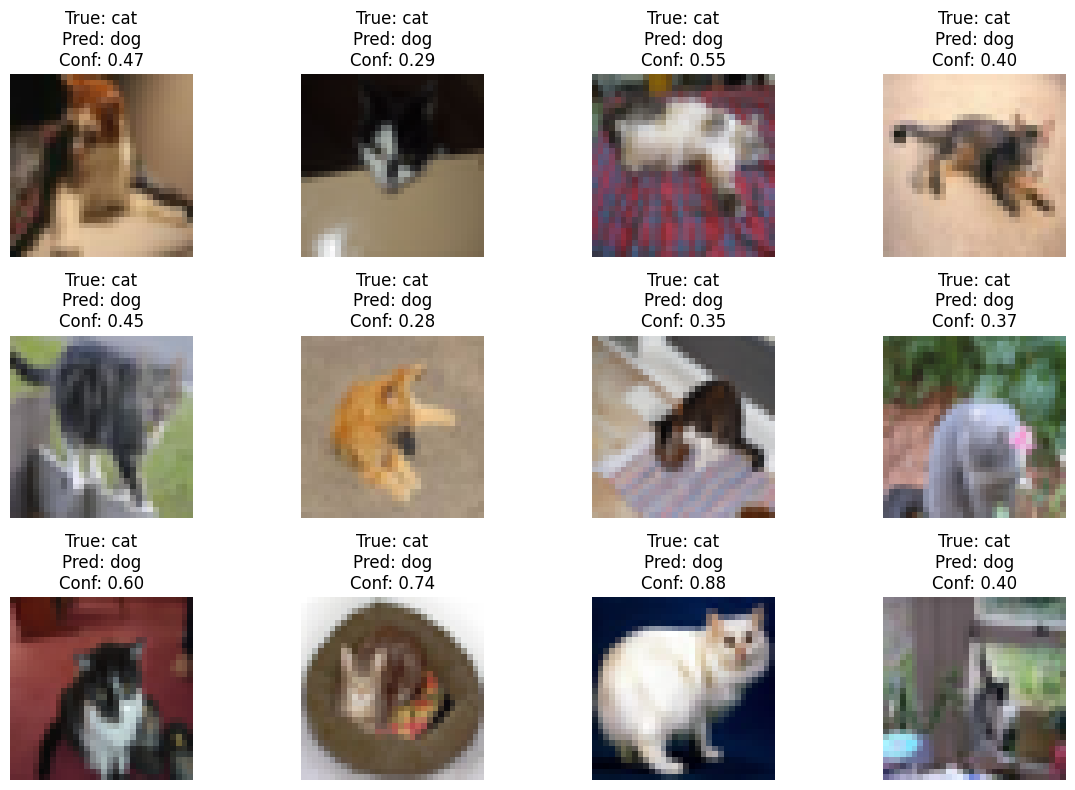

In [130]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(min(12, len(cat_dog_errors))):
    image = cat_dog_errors[i]["image"]

    # CHW → HWC
    image = image.permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[cat_dog_errors[i]['true']]}\n"
        f"Pred: {class_names[cat_dog_errors[i]['predicted']]}\n"
        f"Conf: {cat_dog_errors[i]['confidence']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [131]:
dog_cat_errors = [
    x for x in wrong_examples
    if x["true"] == 5 and x["predicted"] == 3
]

print("Dog → Cat errors:", len(dog_cat_errors))

Dog → Cat errors: 169


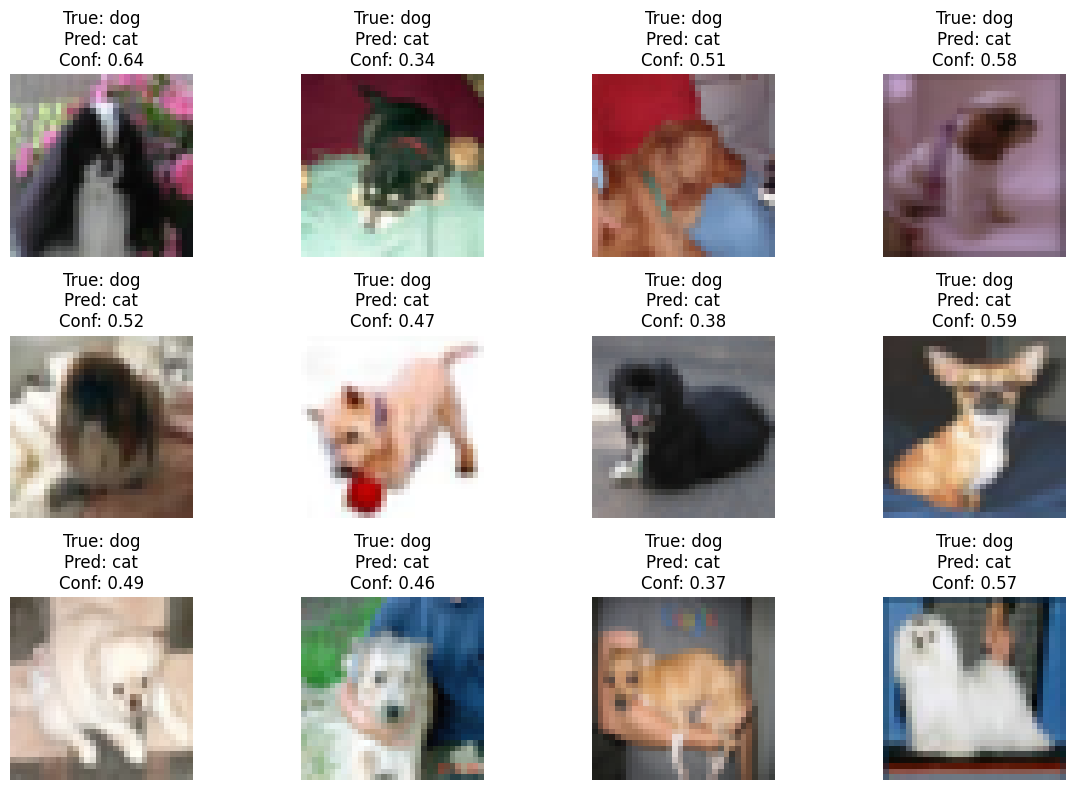

In [132]:
plt.figure(figsize=(12, 8))

for i in range(min(12, len(dog_cat_errors))):
    image = dog_cat_errors[i]["image"]

    # CHW → HWC
    image = image.permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[dog_cat_errors[i]['true']]}\n"
        f"Pred: {class_names[dog_cat_errors[i]['predicted']]}\n"
        f"Conf: {dog_cat_errors[i]['confidence']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [133]:
auto_truck_errors = [
    x for x in wrong_examples
    if x["true"] == 1 and x["predicted"] == 9
]

print("Automobile → Truck errors:", len(auto_truck_errors))

Automobile → Truck errors: 102


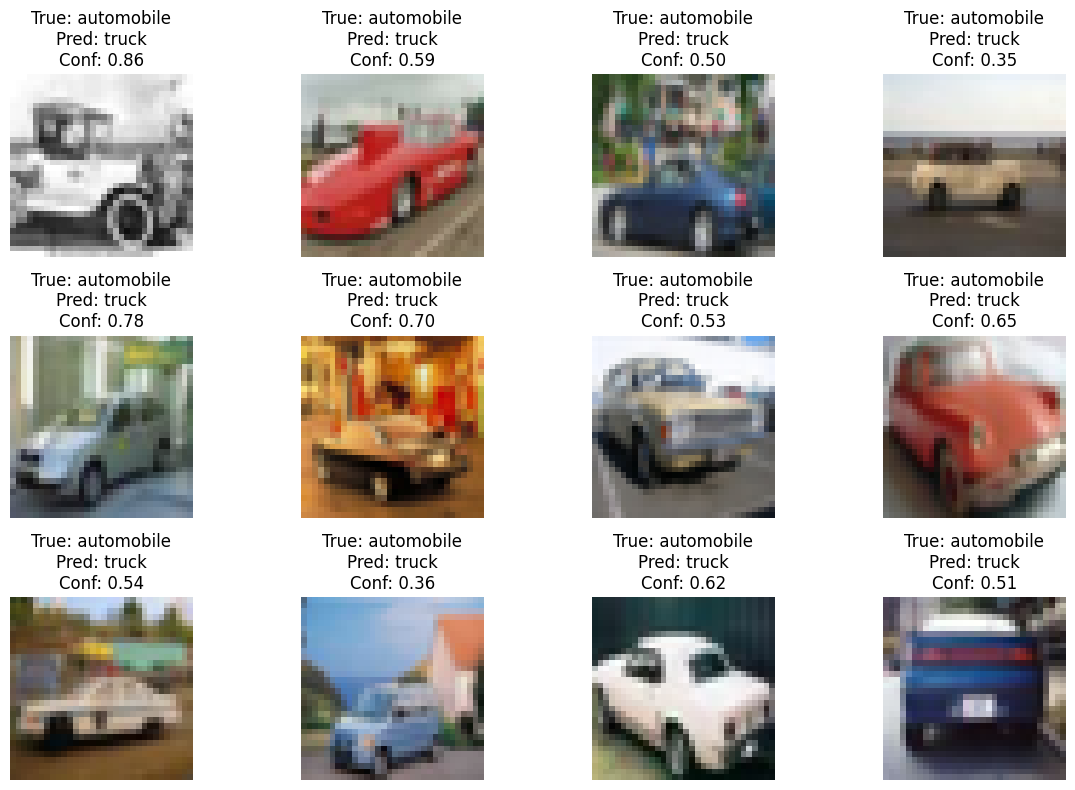

In [134]:
plt.figure(figsize=(12, 8))

for i in range(min(12, len(auto_truck_errors))):
    image = auto_truck_errors[i]["image"]

    # CHW → HWC
    image = image.permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[auto_truck_errors[i]['true']]}\n"
        f"Pred: {class_names[auto_truck_errors[i]['predicted']]}\n"
        f"Conf: {auto_truck_errors[i]['confidence']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [135]:
most_confident_wrong = sorted(
    wrong_examples,
    key=lambda x: x["confidence"],
    reverse=True
)

print("Top 10 most confident wrong predictions:\n")

for i, x in enumerate(most_confident_wrong[:10]):
    print(
        f"{i+1}. True: {class_names[x['true']]:10s} | "
        f"Pred: {class_names[x['predicted']]:10s} | "
        f"Confidence: {x['confidence']:.4f}"
    )

Top 10 most confident wrong predictions:

1. True: automobile | Pred: truck      | Confidence: 0.9921
2. True: ship       | Pred: automobile | Confidence: 0.9906
3. True: bird       | Pred: airplane   | Confidence: 0.9905
4. True: cat        | Pred: truck      | Confidence: 0.9901
5. True: deer       | Pred: horse      | Confidence: 0.9839
6. True: bird       | Pred: airplane   | Confidence: 0.9827
7. True: cat        | Pred: deer       | Confidence: 0.9815
8. True: dog        | Pred: frog       | Confidence: 0.9814
9. True: automobile | Pred: truck      | Confidence: 0.9792
10. True: deer       | Pred: bird       | Confidence: 0.9786


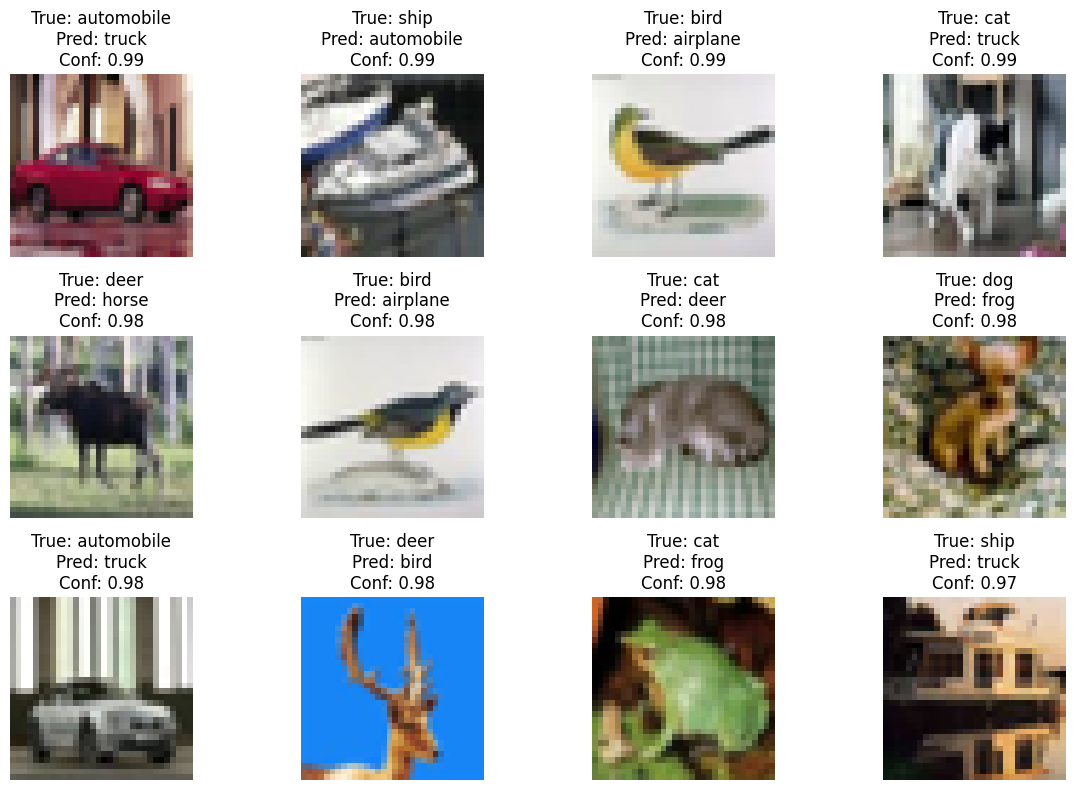

In [136]:
plt.figure(figsize=(12, 8))

for i in range(min(12, len(most_confident_wrong))):
    x = most_confident_wrong[i]

    image = x["image"].permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)

    plt.title(
        f"True: {class_names[x['true']]}\n"
        f"Pred: {class_names[x['predicted']]}\n"
        f"Conf: {x['confidence']:.2f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [137]:
checkpoint_lr_cnn.eval()

correct_confidences = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)
        confidences = probabilities.max(dim=1).values

        for i in range(len(labels)):
            if predictions[i] == labels[i]:
                correct_confidences.append(confidences[i].item())
            else:
                wrong_confidences.append(confidences[i].item())

print("Average confidence - correct:",
      sum(correct_confidences) / len(correct_confidences))

print("Average confidence - wrong:",
      sum(wrong_confidences) / len(wrong_confidences))

print("Highest confidence - wrong:",
      max(wrong_confidences))

Average confidence - correct: 0.7366535381220652
Average confidence - wrong: 0.515606557378288
Highest confidence - wrong: 0.992119550704956
